# 05 — Analiz, Grafikler ve İstatistik (İP-7, İP-8)

Deney klasörlerindeki özet/soru-bazında CSV'lerden rapor tabloları ve grafikler üretir. Bu notebook GPU gerektirmez.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

REPO_URL = 'https://github.com/EmreK37/RAG-Tabanli-Turkce-Soru-Cevap-Sistemleri.git'
BRANCH = 'RAG-dev'
REPO_DIR = '/content/RAG-proje'
if os.path.exists('/content'):
    if not os.path.exists(REPO_DIR):
        !git clone -b {BRANCH} {REPO_URL} {REPO_DIR}
    %cd {REPO_DIR}
    !git pull origin {BRANCH}

klasorler = sorted(Path('results').glob('ana-karsilastirma-*'))
son = klasorler[-1]
ozet = pd.read_csv(son / 'ozet.csv')
soru_yolu = son / 'soru-bazinda.csv'
soru = pd.read_csv(soru_yolu) if soru_yolu.exists() else None
print('Deney:', son)
ozet

Cloning into '/content/RAG-proje'...
remote: Enumerating objects: 139, done.
remote: Counting objects: 100% (139/139), done.
remote: Compressing objects: 100% (98/98), done.
remote: Total 139 (delta 58), reused 103 (delta 30), pack-reused 0 (from 0)
Receiving objects: 100% (139/139), 160.83 KiB | 2.55 MiB/s, done.
Resolving deltas: 100% (58/58), done.
/content/RAG-proje
From https://github.com/EmreK37/RAG-Tabanli-Turkce-Soru-Cevap-Sistemleri
 * branch            RAG-dev    -> FETCH_HEAD
Already up to date.
Deney: results/ana-karsilastirma-20261111-092927


,sistem,indeks_suresi_sn,ort_gecikme_ms,recall@5,recall@10,ndcg@10,mrr@10,hit@5
0,minilm,10.09,12.57,0.8500,0.9083,0.7477,0.6954,0.8500
1,e5-base,17.53,11.81,0.9750,0.9917,0.9246,0.9031,0.9750
2,bge-m3,60.86,20.46,0.9833,0.9917,0.9189,0.8943,0.9833
3,qwen3-0.6b,36.80,62.74,0.9083,0.9417,0.8165,0.7751,0.9083
4,tr-model,10.38,15.76,0.9333,0.9583,0.8336,0.7924,0.9333
5,bm25,0.01,0.41,0.9250,0.9417,0.8479,0.8165,0.9250


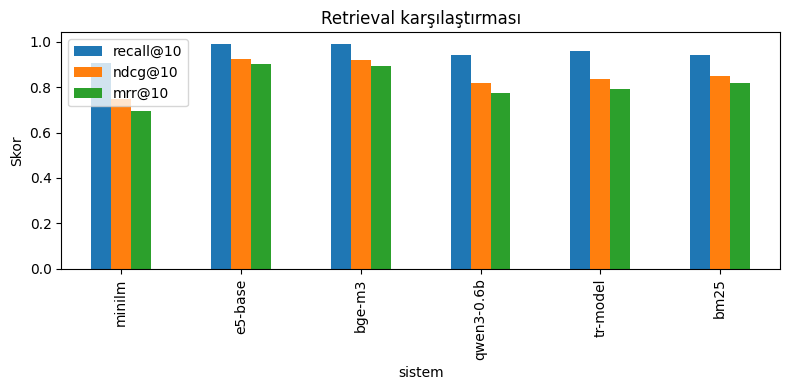

Kaydedildi: results/ana-karsilastirma-20261111-092927/grafik-retrieval.png


In [2]:
# Sistem karşılaştırma grafiği (rapor için PNG kaydeder)
fig, ax = plt.subplots(figsize=(8, 4))
ozet.plot.bar(x='sistem', y=['recall@10', 'ndcg@10', 'mrr@10'], ax=ax)
ax.set_ylabel('Skor')
ax.set_title('Retrieval karşılaştırması')
plt.tight_layout()
plt.savefig(son / 'grafik-retrieval.png', dpi=200)
plt.show()
print('Kaydedildi:', son / 'grafik-retrieval.png')

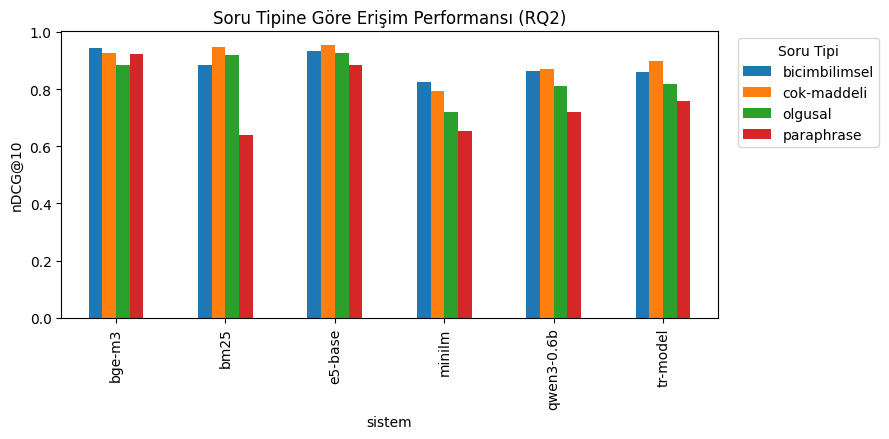

,bicimbilimsel,cok-maddeli,olgusal,paraphrase
sistem,,,,
bge-m3,0.9441,0.9254,0.8841,0.9218
bm25,0.8841,0.9462,0.9206,0.6407
e5-base,0.9350,0.9544,0.9249,0.8842
minilm,0.8256,0.7936,0.7186,0.6531
qwen3-0.6b,0.8632,0.8714,0.8121,0.7193
tr-model,0.8585,0.8977,0.8188,0.7592


In [3]:
# Soru tipine göre kırılım (RQ2): bicimbilimsel/paraphrase sorularda kayıp
if soru is not None:
    ndcg = soru[soru['metrik'] == 'ndcg@10']
    kirilim = ndcg.groupby(['sistem', 'tip'])['skor'].mean().unstack()
else:
    kirilim = pd.read_csv(son / 'rq2-kirilim.csv', index_col='sistem')

fig, ax = plt.subplots(figsize=(9, 4.5))
kirilim.plot.bar(ax=ax)
ax.set_ylabel('nDCG@10')
ax.set_title('Soru Tipine Göre Erişim Performansı (RQ2)')
ax.legend(title='Soru Tipi', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(son / 'grafik-rq2-kirilim.png', dpi=200)
plt.show()
kirilim

=== RQ4: Maliyet ve Gecikme Özeti ===
    sistem  indeks_suresi_sn  ort_gecikme_ms  ndcg@10  recall@5
    minilm             10.09           12.57   0.7477    0.8500
   e5-base             17.53           11.81   0.9246    0.9750
    bge-m3             60.86           20.46   0.9189    0.9833
qwen3-0.6b             36.80           62.74   0.8165    0.9083
  tr-model             10.38           15.76   0.8336    0.9333
      bm25              0.01            0.41   0.8479    0.9250

=== RQ3: RAG Yanıt Kalitesi ve Faithfulness Özeti ===
  sistem  hit@5  faithfulness  answer_correctness  dogru_atif
 e5-base   0.95        0.8964              0.6712        0.75
tr-model   0.70        0.8832              0.6662        0.45
    bm25   0.65        0.8843              0.6630        0.60
  minilm   0.65        0.8597              0.6382        0.60

=== RQ5: Sorguya Duyarlı Router ve Ablasyon Özeti ===
                             sistem  ndcg@10  recall@5  ort_gecikme_ms
                  Route

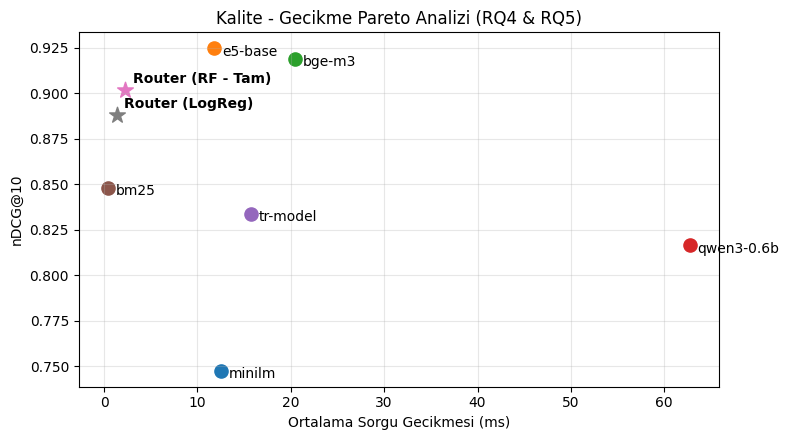

In [4]:
# Maliyet özeti (RQ4) + RQ3 RAG Özeti + RQ5 Router Kalite-Maliyet Pareto Grafiği
print('=== RQ4: Maliyet ve Gecikme Özeti ===')
print(ozet[['sistem', 'indeks_suresi_sn', 'ort_gecikme_ms', 'ndcg@10', 'recall@5']].to_string(index=False))

if Path('results/rq3-rag-ozet.csv').exists():
    print('\n=== RQ3: RAG Yanıt Kalitesi ve Faithfulness Özeti ===')
    print(pd.read_csv('results/rq3-rag-ozet.csv').to_string(index=False))

if Path('results/rq5-router-ozet.csv').exists():
    rq5 = pd.read_csv('results/rq5-router-ozet.csv')
    print('\n=== RQ5: Sorguya Duyarlı Router ve Ablasyon Özeti ===')
    print(rq5.to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for _, r in ozet.iterrows():
        ax.scatter(r['ort_gecikme_ms'], r['ndcg@10'], s=90, label=r['sistem'])
        ax.annotate(r['sistem'], (r['ort_gecikme_ms'] + 0.8, r['ndcg@10'] - 0.004))
    for _, r in rq5[rq5['sistem'].isin(['Router (RF - Tam)', 'Router (LogReg)'])].iterrows():
        ax.scatter(r['ort_gecikme_ms'], r['ndcg@10'], s=140, marker='*', label=r['sistem'])
        ax.annotate(r['sistem'], (r['ort_gecikme_ms'] + 0.8, r['ndcg@10'] + 0.004), fontweight='bold')
    ax.set_xlabel('Ortalama Sorgu Gecikmesi (ms)')
    ax.set_ylabel('nDCG@10')
    ax.set_title('Kalite - Gecikme Pareto Analizi (RQ4 & RQ5)')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(son / 'grafik-rq4-rq5-pareto.png', dpi=200)
    plt.show()

In [ ]:
# A4 (Top-k), A5 (Chunk Boyutu ve İndeks Boyutu), Dış Benchmark ve Kaçınma Analizi Grafikleri
for baslik, dosya in [
    ("A4: Top-k Erişim Ablasyonu", "results/a4-topk-ablasyon.csv"),
    ("A5: Chunk Boyutu ve İndeks Boyutu (KB) Ablasyonu", "results/a5-chunk-ablasyon.csv"),
    ("Bölüm 3: Standart Türkçe Benchmark Karşılaştırması", "results/dis-benchmark-ozet.csv"),
    ("A4: RAG Top-k Yanıt Ablasyonu", "results/a4-rag-topk-ozet.csv"),
    ("Bölüm 6.2: Cevaplanamaz Sorularda Kaçınma (Abstention)", "results/rq3-kacinma-ozet.csv"),
]:
    if Path(dosya).exists():
        print(f"\n=== {baslik} ===")
        print(pd.read_csv(dosya).to_string(index=False))

if Path("results/a4-topk-ablasyon.csv").exists() and Path("results/a5-chunk-ablasyon.csv").exists():
    a4_df = pd.read_csv("results/a4-topk-ablasyon.csv")
    a5_df = pd.read_csv("results/a5-chunk-ablasyon.csv")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for sistem_adi, grp in a4_df.groupby("sistem"):
        axes[0].plot(grp["top_k"], grp["recall"], marker="o", label=sistem_adi)
    axes[0].set_title("A4: Top-k Değerine Göre Recall@k")
    axes[0].set_xlabel("Top-k")
    axes[0].set_ylabel("Recall@k")
    axes[0].set_xticks([1, 3, 5, 10])
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    pivot_a5 = a5_df.pivot(index="sistem", columns="chunk_boyutu", values="ndcg@10")
    pivot_a5.plot(kind="bar", ax=axes[1], rot=0)
    axes[1].set_title("A5: Chunk Boyutuna Göre nDCG@10 (400 / 800 / 1200)")
    axes[1].set_ylabel("nDCG@10")
    axes[1].set_ylim(0.5, 1.05)
    axes[1].grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(son / "grafik-a4-a5-ablasyon.png", dpi=200)
    plt.show()

## Raporlama kontrol listesi (İP-8)

- [ ] Her tabloda kullanılan konfigürasyon ve tohumlar belirtilmiş
- [ ] Sistem çiftleri için eşleştirilmiş bootstrap güven aralıkları eklenmiş
- [ ] Soru tipine göre kırılım (RQ2) ve maliyet analizi (RQ4) dahil
- [ ] Hata analizi: en kötü 10 soru elle incelenip sınıflandırılmış
- [ ] Sonuç klasörleri Drive'a yedeklenmiş ve repoya özet CSV'ler işlenmiş